#SpliceAI2

This collab document wil enable you to run SpliceAI2 in your browser.

Before starting though pleas change runtime type to that with a GPU (e.g. T4), as SpliceAI2 requires a gpu to run. This can be done from the menu in the top right corner of the screen.


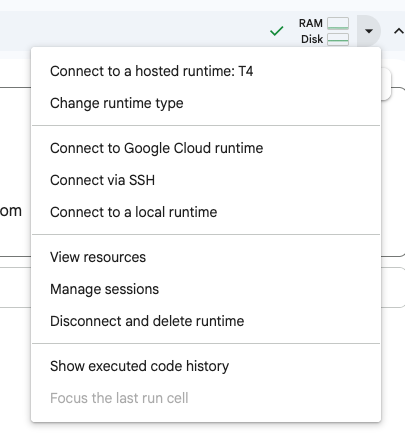

Next install SpliceAI2

In [ ]:
pip install spliceai2

In [ ]:

# @title SpliceAI2 — Model Setup & Download { display-mode: "form" }
# @markdown ## Download SpliceAI2 models
# @markdown This step downloads both SpliceAI2 models for variant prediction.
# @markdown
# @markdown ### 🔑 First-time setup
# @markdown
# @markdown **1. Accept the model licence**
# @markdown
# @markdown Open [SpliceAI2 on Hugging Face](https://huggingface.co/illumina-ai/SpliceAI2).
# @markdown Sign in and review and accept the model's access conditions.
# @markdown Access is restricted to eligible non-commercial research.
# @markdown
# @markdown **2. Create your access token**
# @markdown
# @markdown Open [Hugging Face Tokens](https://huggingface.co/settings/tokens).
# @markdown Create a fine-grained token with read access.
# @markdown Copy your new token.
# @markdown
# @markdown **3. Add your token to Google Colab**
# @markdown
# @markdown - Click the 🔑 **Secrets** icon in the left sidebar.
# @markdown - Create a secret named `HF_TOKEN`.
# @markdown - Paste your Hugging Face token as its value.
# @markdown - Enable **Notebook access** for the secret.
# @markdown
# @markdown **4. Run this cell**
# @markdown
# @markdown Both models will be saved in `/content/SpliceAI2/`.
# @markdown You only need to configure the secret once per notebook.
# @markdown
# @markdown ---
# @markdown ### 📦 Models to download
# @markdown - `spliceai2_multispecies_13M_01`
# @markdown - `spliceai2_multispecies_13M_02`
# @markdown
# @markdown Click ▶ **Run** to begin.

import os
import subprocess
import sys
from pathlib import Path

subprocess.run(
    [sys.executable, "-m", "pip", "-q", "install",
     "-U", "huggingface_hub"],
    check=True
)

from google.colab import userdata
from huggingface_hub import hf_hub_download

# Configuration
repo_id = "illumina-ai/SpliceAI2"
model_dir = Path("/content/SpliceAI2")

models = [
    "spliceai2_multispecies_13M_01/model.ckpt",
    "spliceai2_multispecies_13M_02/model.ckpt"
]

# Retrieve token securely
try:
    token = userdata.get("HF_TOKEN")
except Exception as e:
    raise RuntimeError(
        "❌ Hugging Face token not found or access denied.\n"
        "Follow the setup instructions above and "
        "enable notebook access to HF_TOKEN."
    ) from e

if not token:
    raise ValueError(
        "❌ HF_TOKEN is empty. Add your Hugging Face "
        "token to Colab Secrets."
    )

# Download both checkpoints
model_dir.mkdir(parents=True, exist_ok=True)

for i, model_file in enumerate(models, 1):
    print(f"\n⬇️ Downloading model {i}/2: {model_file}")

    try:
        local_path = hf_hub_download(
            repo_id=repo_id,
            filename=model_file,
            token=token,
            local_dir=str(model_dir)
        )
        print(f"✅ Saved: {local_path}")

    except Exception as e:
        raise RuntimeError(
            f"Failed to download {model_file}.\n"
            "Check that you have accepted the "
            "SpliceAI2 model terms and that your "
            "token has read access."
        ) from e

print("\n✅ Both SpliceAI2 models are ready!")

model_01 = str(model_dir / models[0])
model_02 = str(model_dir / models[1])

print("\nModel 1:", model_01)
print("Model 2:", model_02)


In [ ]:

# @title Download GRCh38 from DDBJ { display-mode: "form" }

import os
import subprocess

# Install dependencies
subprocess.run(
    ["apt-get", "install", "-y", "-qq", "aria2", "samtools"],
    check=True
)

url = "https://ddbj.nig.ac.jp/public/public-human-genomes/GRCh38/fasta/hg38.fa.gz"

gz_path = "/content/hg38.fa.gz"
fasta_path = "/content/hg38.fa"

# Download with parallel connections
if not os.path.exists(fasta_path):
    print("⬇️ Downloading GRCh38 from DDBJ...")

    subprocess.run([
        "aria2c",
        "-x", "16",             # Max connections
        "-s", "16",             # Split download
        "-k", "1M",             # Minimum split size
        "-c",                  # Resume interrupted downloads
        "--file-allocation=none",
        "-d", "/content",
        "-o", "hg38.fa.gz",
        url
    ], check=True)

    print("📦 Decompressing genome...")
    subprocess.run(["gzip", "-dk", gz_path], check=True)

# Index FASTA
if not os.path.exists(fasta_path + ".fai"):
    print("🔬 Indexing reference...")
    subprocess.run(
        ["samtools", "faidx", fasta_path],
        check=True
    )

print("✅ GRCh38 reference ready!")
print("FASTA:", fasta_path)
print("Index:", fasta_path + ".fai")


In [ ]:

# @title Variant TSV Generator { display-mode: "form" }
# @markdown ### Enter your variant details and run cell

chrom = "chr4" # @param {type:"string"}
pos = 108028042 # @param {type:"integer"}
ref = "ATCC" # @param {type:"string"}
alt = "GTGCTTTTGATTAAAAGGTT" # @param {type:"string"}

import pandas as pd
from IPython.display import display

# Validate inputs
chrom = chrom.strip()
ref = ref.strip().upper()
alt = alt.strip().upper()

if not chrom or pos < 1:
    raise ValueError("Enter a valid chromosome and positive position.")

if not ref or not alt or any(c not in "ACGT" for c in ref + alt):
    raise ValueError("REF and ALT must contain only A, C, G, T.")

# Generate both strand rows
df = pd.DataFrame([
    {"chrom": chrom, "pos": pos, "ref": ref, "alt": alt, "strand": "+"},
    {"chrom": chrom, "pos": pos, "ref": ref, "alt": alt, "strand": "-"}
])

# Automatically save in Colab
tsv_path = "/content/variants.tsv"
df.to_csv(tsv_path, sep="\t", index=False)

print(f"✅ TSV saved successfully to {tsv_path}")
display(df)


In [ ]:

# @title Run SpliceAI2 Variant Predictions { display-mode: "form" }
# @markdown ### SpliceAI2 prediction
# @markdown This step uses both pretrained SpliceAI2 models to
# @markdown predict the splicing effects of your submitted variant.
# @markdown
# @markdown **Before running:**
# @markdown - Generate your variants TSV
# @markdown - Download the GRCh38 reference genome
# @markdown - Download both SpliceAI2 models
# @markdown - Enable a GPU under Runtime → Change runtime type
# @markdown
# @markdown ---
# @markdown ### Prediction settings
# @markdown These have been optimised for the NVIDIA Tesla T4 (15 GB VRAM) and
# @markdown **do not** need to be modified unless you get an out of memory error.

input_length = 155648 # @param {type:"integer"}
junction_positions = 1024 # @param {type:"integer"}
skip_compilation = True # @param {type:"boolean"}

import os
import sys
import subprocess
from pathlib import Path
from IPython.display import display
import pandas as pd

# Install SpliceAI2 if not already installed
subprocess.run(
    [sys.executable, "-m", "pip", "-q",
     "install", "spliceai2"],
    check=True
)

# Define input paths
model_01 = "/content/SpliceAI2/spliceai2_multispecies_13M_01"
model_02 = "/content/SpliceAI2/spliceai2_multispecies_13M_02"

variants_tsv = "/content/variants.tsv"
reference_fasta = "/content/hg38.fa"

# Check all required files exist
required_files = [
    f"{model_01}/model.ckpt",
    f"{model_02}/model.ckpt",
    variants_tsv,
    reference_fasta
]

missing = [p for p in required_files if not os.path.isfile(p)]

if missing:
    raise FileNotFoundError(
        "Missing required files:\n" + "\n".join(missing)
    )

# Check GPU
import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU not detected. In Colab, select "
        "Runtime → Change runtime type → T4 GPU "
        "and rerun your setup cells."
    )

print("✅ GPU:", torch.cuda.get_device_name(0))
print("✅ All inputs found")
print("\n🔬 Running SpliceAI2...\n")

# Build command
cmd = [
    "spliceai2",
    "--model_folders", model_01, model_02,
    "--var_tsv_file", variants_tsv,
    "--fasta_file", reference_fasta,
    "--in_len", str(input_length),
    "--out_2d_len", str(junction_positions)
]

if skip_compilation:
    cmd.append("--no_compile")

# Configure PyTorch memory allocation
env = os.environ.copy()
env["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"

# Execute prediction
result = subprocess.run(
    cmd,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

# Display output and catch errors
if result.returncode != 0:
    print(result.stdout[-12000:])
    raise RuntimeError(
        f"SpliceAI2 failed with exit code {result.returncode}"
    )

print("✅ SpliceAI2 predictions complete!")

# Load prediction results
output_path = variants_tsv + ".spliceai2"

if not os.path.isfile(output_path):
    raise FileNotFoundError(
        f"Expected output not found: {output_path}"
    )

results = pd.read_csv(output_path, sep="\t")

print("📁 Results saved to:", output_path)

# Display key results
summary_cols = [
    "chrom", "pos", "ref", "alt", "strand",
    "spliceai2_summary_score"
]

display(results[
    [c for c in summary_cols if c in results.columns]
])


In [ ]:


# @title SpliceAI2 — Visualise Prediction Results { display-mode: "form" }
# @markdown ### SpliceAI2 variant effect summary
# @markdown Displays the strongest prediction for each of the
# @markdown six splicing effects across both strands.
# @markdown
# @markdown **Colour thresholds:**
# @markdown - 🟢 Green: score ≥ 0.10
# @markdown - 🟡 Yellow: score ≥ 0.25
# @markdown - 🔴 Red: score ≥ 0.50

import pandas as pd
from pathlib import Path
from IPython.display import display, HTML
from html import escape

# Load prediction results
output_path = Path("/content/variants.tsv.spliceai2")

if not output_path.exists():
    raise FileNotFoundError(
        f"SpliceAI2 results not found: {output_path}"
    )

results = pd.read_csv(output_path, sep="\t")

# Select strand with the highest overall SpliceAI2 score
score_column = "spliceai2_summary_score"

if score_column not in results.columns:
    raise ValueError(
        f"Missing {score_column}. Check the output columns."
    )

results[score_column] = pd.to_numeric(
    results[score_column], errors="coerce"
)

if results[score_column].isna().all():
    raise ValueError("No valid summary scores found.")

# Select strongest strand for each unique variant
variant_columns = ["chrom", "pos", "ref", "alt"]

selected = (
    results.sort_values(
        score_column, ascending=False,
        kind="stable", na_position="last"
    )
    .drop_duplicates(subset=variant_columns)
)

effects = {
    "DG": ("Donor gain", "donor_gain"),
    "DL": ("Donor loss", "donor_loss"),
    "AG": ("Acceptor gain", "acceptor_gain"),
    "AL": ("Acceptor loss", "acceptor_loss"),
    "JG": ("Junction gain", "jxn_gain"),
    "JL": ("Junction loss", "jxn_loss")
}

def score_colour(value):
    if pd.isna(value):
        return "background-color: #eef2f5; color: #344054;"
    if value >= 0.50:
        return "background-color: #ffd1d1; color: #991b1b;"
    if value >= 0.25:
        return "background-color: #fff0b8; color: #854d0e;"
    if value >= 0.10:
        return "background-color: #d5f0dc; color: #166534;"
    return "background-color: #eef2f5; color: #344054;"

def fmt_dist(value):
    number = pd.to_numeric(value, errors="coerce")
    if pd.isna(number):
        return "—"
    return f"{int(number):+d} bp"

summary_rows = []

for _, variant in selected.iterrows():

    name = (
        f"{variant['chrom']}:{variant['pos']} "
        f"{variant['ref']}>{variant['alt']}"
    )
    strand = variant["strand"]
    overall = variant[score_column]

    display(HTML(
        f"<h3>🧬 {escape(name)} — "
        f"Selected strand: {escape(str(strand))}</h3>"
        f"<p><b>SpliceAI2 summary score: "
        f"{overall:.4f}</b></p>"
    ))

    rows = []

    for short, (description, prefix) in effects.items():
        score = pd.to_numeric(
            variant.get(f"{prefix}_delta_score_0"),
            errors="coerce"
        )

        if prefix.startswith("jxn_"):
            distance = (
                f"Donor: {fmt_dist(variant.get(f'{prefix}_donor_dist_0'))}"
                f" | Acceptor: "
                f"{fmt_dist(variant.get(f'{prefix}_acceptor_dist_0'))}"
            )
        else:
            distance = fmt_dist(
                variant.get(f"{prefix}_dist_0")
            )

        rows.append({
            "Effect": short,
            "Description": description,
            "Delta score": score,
            "Distance": distance
        })

        summary_rows.append({
            "chrom": variant["chrom"],
            "pos": variant["pos"],
            "ref": variant["ref"],
            "alt": variant["alt"],
            "strand": strand,
            "effect": short,
            "delta_score": score,
            "distance": distance,
            "spliceai2_summary_score": overall
        })

    table = pd.DataFrame(rows)

    styled = (
        table.style
        .map(score_colour, subset=["Delta score"])
        .format({"Delta score": "{:.4f}"}, na_rep="—")
        .hide(axis="index")
        .set_properties(**{
            "text-align": "center",
            "padding": "10px"
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#253447"),
                    ("color", "white"),
                    ("padding", "10px"),
                    ("text-align", "center")
                ]
            }
        ])
    )

    display(styled)

# Save only selected strand predictions
summary = pd.DataFrame(summary_rows)
summary_path = "/content/spliceai2_strongest_strand.tsv"
summary.to_csv(summary_path, sep="\t", index=False)

print("✅ Strongest-strand summary saved to:", summary_path)
